# SUNS – Zadanie č. 1
## Predikcia dokončenia nákupu v e-shope

Cieľom je predikovať premennú `Revenue`, teda či sa návšteva e-shopu skončí nákupom. Notebook obsahuje čistenie dát, jednoduchý klasifikačný model, EDA a neurónové siete vrátane ukážky pretrénovania a jeho obmedzenia pomocou Early Stopping.

In [12]:
import sys
from pathlib import Path

import copy
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src" / "data_preparation.py").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Nenašiel sa koreň projektu.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_preparation import clean_data, find_invalid_rows, load_data
from src.eda import plot_bounce_vs_exit_rates, plot_purchase_rate_by_visitor_type, setup_plot_style

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
setup_plot_style()

## 1. Načítanie dát a predspracovanie

Pred modelovaním odstránime identifikátor session, stĺpec s veľkým podielom chýbajúcich hodnôt a záznamy, ktoré porušujú významové obmedzenia. Chýbajúci typ návštevníka ponechávame ako samostatnú kategóriu `Unknown`, aby sa nestratila informácia o chýbaní hodnoty.

In [13]:
df_raw = load_data()

missing = df_raw.isna().sum().sort_values(ascending=False)
print(f"Pôvodný dataset: {df_raw.shape[0]:,} riadkov × {df_raw.shape[1]} stĺpcov")
display(pd.DataFrame({"chýbajúce hodnoty": missing[missing.gt(0)]}))
print(f"Riadky s neplatnou hodnotou: {find_invalid_rows(df_raw).sum()}")

df = clean_data(df_raw)
print()
print(f"Očistený dataset: {df.shape[0]:,} riadkov × {df.shape[1]} stĺpcov")
print(f"Chýbajúce hodnoty po čistení: {df.isna().sum().sum()}")
display(df.head())

Pôvodný dataset: 12,333 riadkov × 19 stĺpcov


,chýbajúce hodnoty
Informational_Duration,8139
VisitorType,492
ProductRelated_Duration,246


Riadky s neplatnou hodnotou: 18
Invalid rows removed: 18
Rows removed due to missing ProductRelated_Duration: 245

Očistený dataset: 12,070 riadkov × 17 stĺpcov
Chýbajúce hodnoty po čistení: 0


,Administrative,Administrative_Duration,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,1.0,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,2.0,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,1.0,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,2.0,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,10.0,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Unknown,True,False


Stĺpec `Informational_Duration` má približne dve tretiny chýbajúcich hodnôt, preto ho nie je vhodné nahrádzať odhadom. Riadky s chýbajúcim `ProductRelated_Duration` odstraňujeme, pretože ide o malý podiel dát a nula by znamenala inú informáciu než neznáme trvanie.

## 2. Príprava vstupov a rozdelenie dát

Kategorické stĺpce `Month` a `VisitorType` kódujeme one-hot kódovaním. Dáta delíme stratifikovane v pomere 70 % / 15 % / 15 %, aby bol podiel nákupov v každej množine porovnateľný. Škálovač učíme iba na trénovacej množine.

In [14]:
model_df = pd.get_dummies(
    df,
    columns=["Month", "VisitorType"],
    dtype=int,
)
model_df["Weekend"] = model_df["Weekend"].astype(int)
model_df["Revenue"] = model_df["Revenue"].astype(int)

X = model_df.drop(columns="Revenue")
y = model_df["Revenue"]

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, stratify=y_holdout, random_state=SEED
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

split_summary = pd.DataFrame(
    {
        "množina": ["train", "validácia", "test"],
        "riadky": [len(y_train), len(y_val), len(y_test)],
        "podiel nákupov (%)": [100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()],
    }
)
display(split_summary.round(2))

,množina,riadky,podiel nákupov (%)
0,train,8449,15.81
1,validácia,1810,15.80
2,test,1811,15.85


## 3. Jednoduchý model: logistická regresia

Logistická regresia slúži ako interpretovateľný baseline. Okrem accuracy sledujeme Recall a F1 pre triedu nákupov, pretože triedy sú nevyvážené.

,množina,accuracy,recall (nákup),F1 (nákup)
0,train,0.884,0.394,0.518
1,validácia,0.884,0.350,0.488
2,test,0.884,0.383,0.512


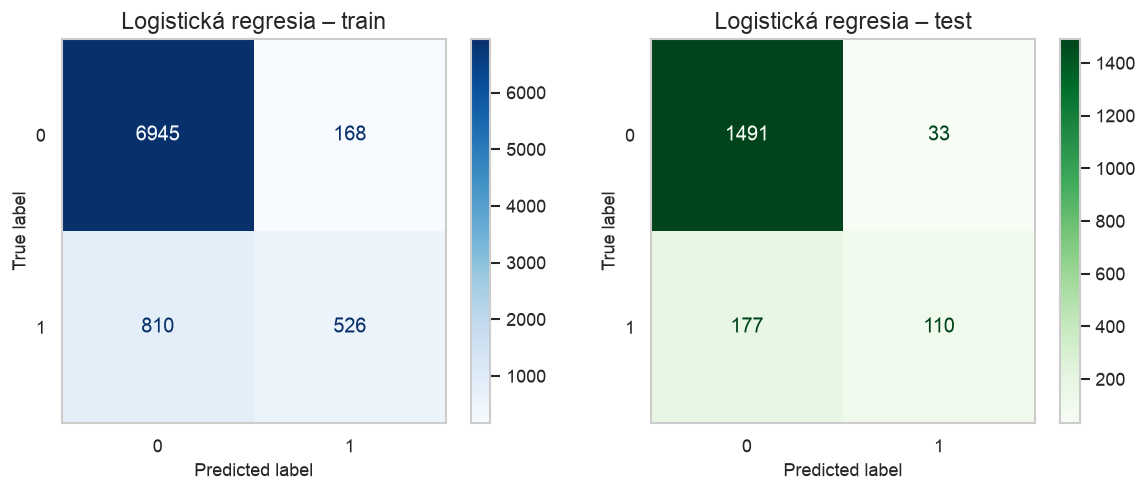

              precision    recall  f1-score   support

  bez nákupu       0.89      0.98      0.93      1524
       nákup       0.77      0.38      0.51       287

    accuracy                           0.88      1811
   macro avg       0.83      0.68      0.72      1811
weighted avg       0.87      0.88      0.87      1811



In [22]:
baseline = LogisticRegression(max_iter=2000, random_state=SEED)
baseline.fit(X_train_s, y_train)

baseline_rows = []
for name, features, target in [
    ("train", X_train_s, y_train),
    ("validácia", X_val_s, y_val),
    ("test", X_test_s, y_test),
]:
    pred = baseline.predict(features)
    baseline_rows.append(
        {
            "množina": name,
            "accuracy": accuracy_score(target, pred),
            "recall (nákup)": recall_score(target, pred, zero_division=0),
            "F1 (nákup)": f1_score(target, pred, zero_division=0),
        }
    )

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, features, target, color in [
    (axes[0], "train", X_train_s, y_train, "Blues"),
    (axes[1], "test", X_test_s, y_test, "Greens"),
]:
    ConfusionMatrixDisplay.from_predictions(target, baseline.predict(features), ax=ax, cmap=color)
    ax.set_title(f"Logistická regresia – {name}")
    ax.grid(False)
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    baseline.predict(X_test_s),
    target_names=["bez nákupu", "nákup"],
    zero_division=0,
))

Vysoká accuracy sama osebe nestačí: väčšina sessions sa nákupom nekončí. Recall ukazuje, akú časť skutočných nákupov model zachytil, a F1 spája presnosť a úplnosť pre túto menšinovú triedu.

### Experiment: vplyv veľkosti trénovacej množiny

Pre viac veľkostí testovacej množiny zopakujeme fit rovnakého baseline. Test vždy oddeľujeme stratifikovane a škálovanie robíme nanovo iba z trénovacích dát.

In [16]:
experiment_rows = []
for test_fraction in [0.10, 0.20, 0.30, 0.50, 0.70]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_fraction, stratify=y, random_state=SEED
    )
    split_scaler = StandardScaler()
    X_tr_s = split_scaler.fit_transform(X_tr)
    X_te_s = split_scaler.transform(X_te)

    model = LogisticRegression(max_iter=2000, random_state=SEED)
    model.fit(X_tr_s, y_tr)
    test_pred = model.predict(X_te_s)
    experiment_rows.append(
        {
            "test podiel": test_fraction,
            "train riadky": len(y_tr),
            "test riadky": len(y_te),
            "test accuracy": accuracy_score(y_te, test_pred),
            "test recall": recall_score(y_te, test_pred, zero_division=0),
            "test F1": f1_score(y_te, test_pred, zero_division=0),
        }
    )

split_experiments = pd.DataFrame(experiment_rows)
display(split_experiments.round(3))

,test podiel,train riadky,test riadky,test accuracy,test recall,test F1
0,0.1,10863,1207,0.883,0.382,0.509
1,0.2,9656,2414,0.886,0.382,0.516
2,0.3,8449,3621,0.884,0.366,0.500
3,0.5,6035,6035,0.884,0.373,0.505
4,0.7,3621,8449,0.883,0.379,0.505


Výsledky sú stabilné aj pri zmenách veľkosti tréningovej vzorky: test accuracy sa pohybuje približne medzi 0,883 a 0,886 a Recall nákupu medzi 0,366 a 0,382. V tomto rozsahu sa pri logistickej regresii neobjavuje výrazný rozdiel medzi režimami delenia dát.

## 4. Prieskumná analýza dát

Nasledujúce grafy skúmajú mieru nákupu podľa typu návštevníka, rozdiel v `PageValues` a vzťah medzi `BounceRates` a `ExitRates`.

Figure saved to: /Users/polo/workspace/suns-zad-1/results/figures/eda_purchase_rate_by_visitor_type.png
Figure saved to: /Users/polo/workspace/suns-zad-1/results/figures/eda_bounce_vs_exit_rates.png


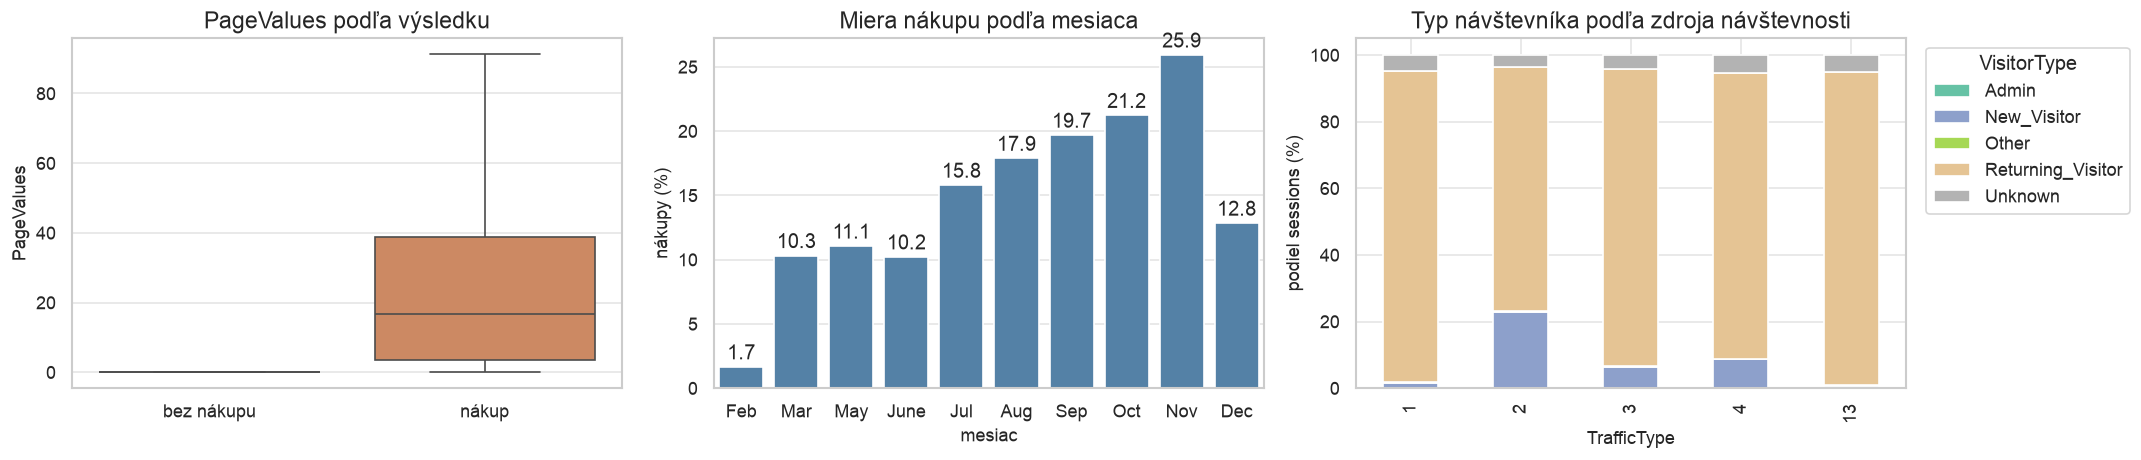

,VisitorType,sessions,purchases,purchase_rate
0,New_Visitor,1593,422,26.49
1,Other,78,16,20.51
2,Returning_Visitor,9912,1471,14.84
3,Admin,1,0,0.00
4,Unknown,486,0,0.00


,relationship,sessions,pearson_correlation,spearman_correlation
0,BounceRates vs ExitRates,12070,0.913,0.601


,sessions,purchase_rate
Month,,
Feb,181,1.66
Mar,1862,10.31
May,3302,11.05
June,284,10.21
Jul,418,15.79
Aug,425,17.88
Sep,437,19.68
Oct,542,21.22
Nov,2936,25.92


VisitorType,Admin,New_Visitor,Other,Returning_Visitor,Unknown
TrafficType,,,,,
1,0.0,1.5,0.2,93.5,4.8
2,0.0,23.0,0.3,73.3,3.5
3,0.0,6.4,0.4,89.2,4.1
4,0.0,8.8,0.0,85.7,5.5
13,0.0,0.7,0.1,94.1,5.0


In [23]:
visitor_summary = plot_purchase_rate_by_visitor_type(df)
bounce_summary = plot_bounce_vs_exit_rates(df)

page_values_plot = df.assign(výsledok=np.where(df["Revenue"], "nákup", "bez nákupu"))
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.boxplot(
    data=page_values_plot,
    x="výsledok",
    y="PageValues",
    order=["bez nákupu", "nákup"],
    showfliers=False,
    hue="výsledok",
    legend=False,
    ax=axes[0],
)
axes[0].set(title="PageValues podľa výsledku", xlabel="")

month_summary = (
    df.groupby("Month", observed=True)["Revenue"]
    .agg(sessions="size", purchase_rate="mean")
    .assign(purchase_rate=lambda table: 100 * table["purchase_rate"])
    .reindex(["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    .dropna()
)
sns.barplot(
    x=month_summary.index,
    y=month_summary["purchase_rate"],
    color="steelblue",
    ax=axes[1],
)
axes[1].set(title="Miera nákupu podľa mesiaca", xlabel="mesiac", ylabel="nákupy (%)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f", padding=2)

top_traffic = df["TrafficType"].value_counts().head(5).index
traffic_mix = pd.crosstab(
    df.loc[df["TrafficType"].isin(top_traffic), "TrafficType"],
    df.loc[df["TrafficType"].isin(top_traffic), "VisitorType"],
    normalize="index",
).mul(100)
traffic_mix.plot(kind="bar", stacked=True, ax=axes[2], colormap="Set2")
axes[2].set(
    title="Typ návštevníka podľa zdroja návštevnosti",
    xlabel="TrafficType",
    ylabel="podiel sessions (%)",
)
axes[2].legend(title="VisitorType", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

display(visitor_summary.round(2))
display(bounce_summary.round(4))
display(month_summary.round(2))
display(traffic_mix.round(1))

### Interpretácia EDA

1. **Typ návštevníka a nákup:** noví návštevníci majú vyššiu mieru nákupu než vracajúci sa návštevníci. Pri kategóriách s malým počtom sessions treba záver čítať opatrne.
2. **PageValues a Revenue:** sessions zakončené nákupom majú výrazne vyššie PageValues. Ide o prakticky užitočný prediktor, ktorý zachytáva hodnotu navštívených stránok.
3. **BounceRates a ExitRates:** Pearsonova korelácia je približne 0,913, preto tieto metriky rastú spolu. Spearmanova korelácia je nižšia, čo ukazuje, že vzťah nie je dokonale monotónny.
4. **Mesiac a miera nákupu:** mesačný graf ukazuje sezónne rozdiely v percentuálnom podiele nákupov. Uvádzame mieru nákupu, nie iba absolútny počet konverzií, aby rozdielne veľké mesačné vzorky neskreslili porovnanie.
5. **TrafficType a VisitorType:** päť najčastejších zdrojov návštevnosti má odlišné zastúpenie nových a vracajúcich sa návštevníkov. Vzťah je mimo cieľovej premennej a ukazuje, že kanál návštevnosti súvisí so skladbou publika.

## 5. Neurónová sieť

Použijeme plne prepojenú sieť pre tabuľkové dáta. Na validáciu vývoja používame validačnú množinu; test ostáva odložený až na záverečné vyhodnotenie.

In [18]:
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_t = torch.tensor(y_val.to_numpy(), dtype=torch.long)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.long)

class PurchaseNet(nn.Module):
    def __init__(self, n_features, hidden_layers, dropout=0.0):
        super().__init__()
        layers = []
        previous = n_features
        for width in hidden_layers:
            layers.extend([nn.Linear(previous, width), nn.ReLU()])
            if dropout:
                layers.append(nn.Dropout(dropout))
            previous = width
        layers.append(nn.Linear(previous, 2))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

def evaluate_network(network, features, target):
    network.eval()
    with torch.no_grad():
        prediction = network(features).argmax(dim=1).cpu().numpy()
    truth = target.cpu().numpy()
    return {
        "accuracy": accuracy_score(truth, prediction),
        "recall": recall_score(truth, prediction, zero_division=0),
        "f1": f1_score(truth, prediction, zero_division=0),
        "pred": prediction,
    }

def train_network(network, epochs, lr, early_stopping=None):
    optimizer = torch.optim.Adam(network.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": []}
    best_weights = copy.deepcopy(network.state_dict())
    best_val_loss = float("inf")
    stale_epochs = 0

    for epoch in range(epochs):
        network.train()
        optimizer.zero_grad()
        loss = criterion(network(X_train_t), y_train_t)
        loss.backward()
        optimizer.step()

        network.eval()
        with torch.no_grad():
            val_loss = criterion(network(X_val_t), y_val_t).item()
        history["train_loss"].append(loss.item())
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(network.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
            if early_stopping is not None and stale_epochs >= early_stopping:
                break

    if early_stopping is not None:
        network.load_state_dict(best_weights)
    return history, epoch + 1, best_val_loss

### Zámerné pretrénovanie

Veľká architektúra bez regularizácie a pevný vysoký počet epoch vytvára podmienky pre pretrénovanie. Dôkazom nie je len training loss, ale rozdiel medzi tréningovou a validačnou krivkou a medzi metrikami na trénovacej a testovacej množine.

,množina,accuracy,recall,f1
0,train,0.947,0.892,0.842
1,test,0.885,0.662,0.645


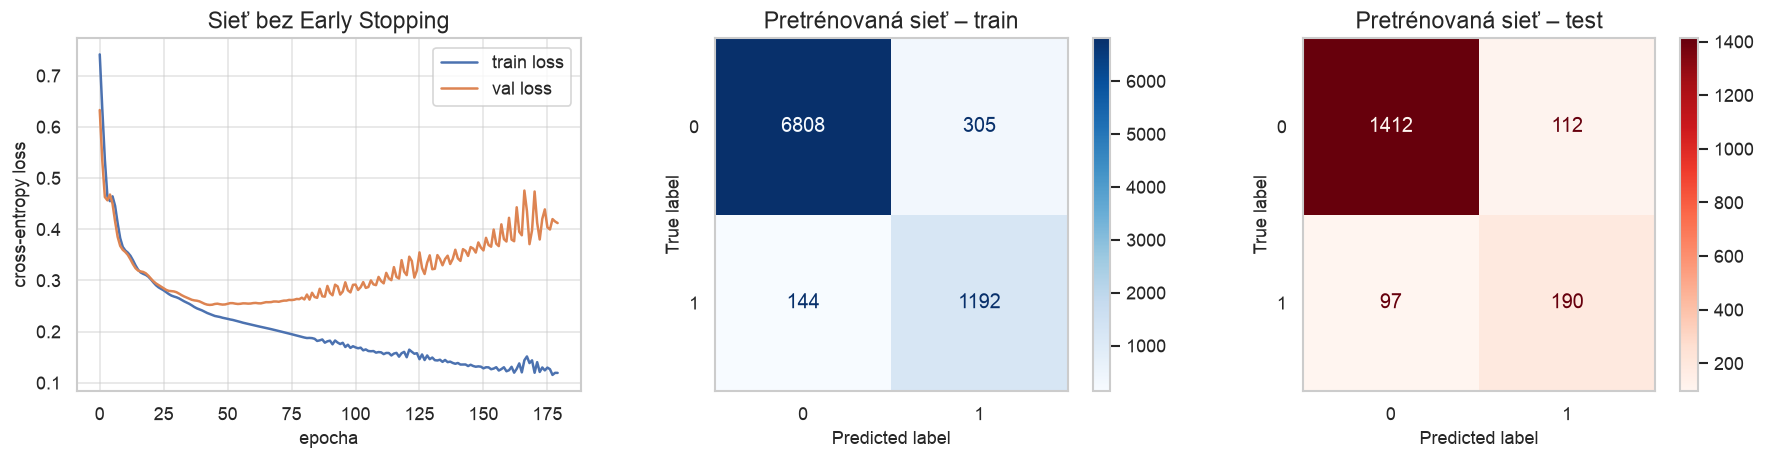

In [24]:
torch.manual_seed(SEED)
overfit_model = PurchaseNet(X_train_s.shape[1], [256, 128, 64])
overfit_history, overfit_epochs, _ = train_network(
    overfit_model, epochs=180, lr=0.003, early_stopping=None
)

overfit_train = evaluate_network(overfit_model, X_train_t, y_train_t)
overfit_test = evaluate_network(overfit_model, X_test_t, y_test_t)
display(pd.DataFrame([
    {"množina": "train", **{k: overfit_train[k] for k in ["accuracy", "recall", "f1"]}},
    {"množina": "test", **{k: overfit_test[k] for k in ["accuracy", "recall", "f1"]}},
]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(overfit_history["train_loss"], label="train loss")
axes[0].plot(overfit_history["val_loss"], label="val loss")
axes[0].set(title="Sieť bez Early Stopping", xlabel="epocha", ylabel="cross-entropy loss")
axes[0].legend()

for ax, name, target, score, color in [
    (axes[1], "train", y_train, overfit_train, "Blues"),
    (axes[2], "test", y_test, overfit_test, "Reds"),
]:
    ConfusionMatrixDisplay.from_predictions(target, score["pred"], ax=ax, cmap=color)
    ax.set_title(f"Pretrénovaná sieť – {name}")
    ax.grid(False)

plt.tight_layout()
plt.show()

Sieť bez obmedzenia dosiahla Recall 0,892 na trénovacích dátach, ale 0,662 na teste. Rozdiel spolu s priebehom loss potvrdzuje pretrénovanie: model sa prispôsobil tréningovým vzorom viac, než dokáže preniesť na nové sessions.

Ak validačná chyba po skoršom minime rastie, ďalšie učenie zlepšuje zapamätanie trénovacích dát, ale zhoršuje zovšeobecnenie. Preto ďalší model zastavíme podľa validačnej chyby a obnovíme jeho najlepšie váhy.

### Early Stopping

Trénovanie skončí, ak sa validačná chyba nezlepší počas 18 po sebe idúcich epoch. Po skončení sa obnovia váhy z najlepšej validačnej epochy.

,množina,accuracy,recall,f1
0,train,0.906,0.671,0.693
1,test,0.901,0.613,0.662


Early Stopping po 108 epochách; najlepší validačný loss: 0.2401


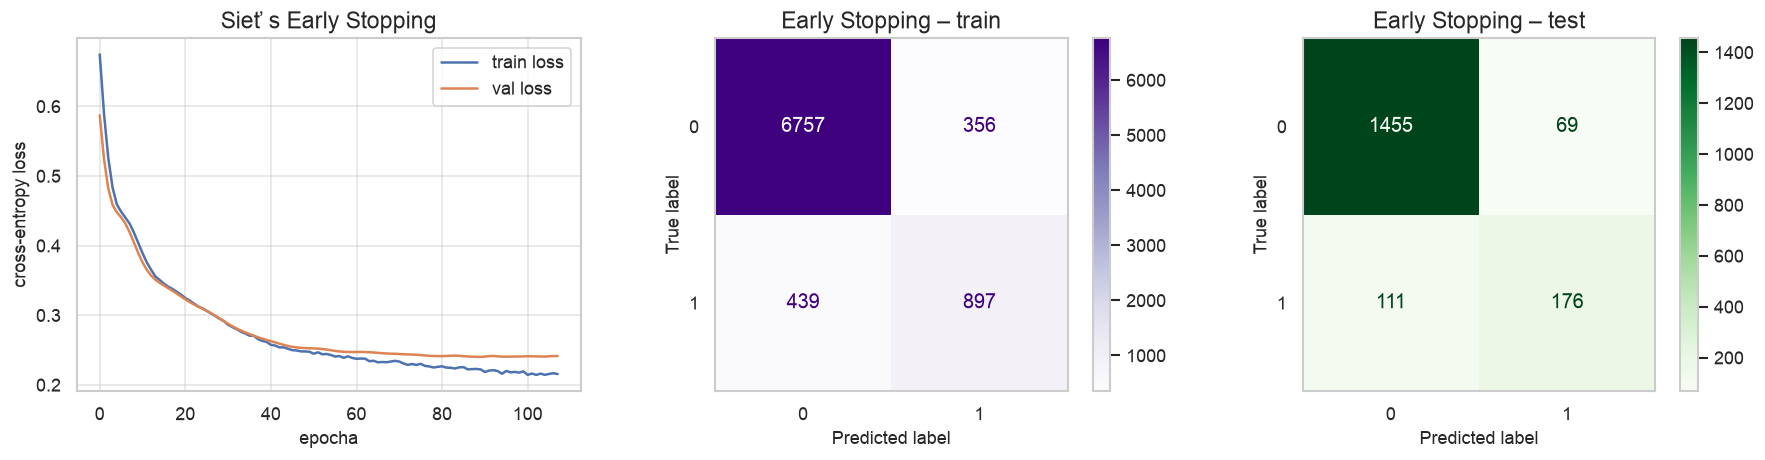

In [25]:
torch.manual_seed(SEED)
early_model = PurchaseNet(X_train_s.shape[1], [128, 64], dropout=0.10)
early_history, early_epochs, best_val_loss = train_network(
    early_model, epochs=250, lr=0.003, early_stopping=18
)

early_train = evaluate_network(early_model, X_train_t, y_train_t)
early_test = evaluate_network(early_model, X_test_t, y_test_t)
display(pd.DataFrame([
    {"množina": "train", **{k: early_train[k] for k in ["accuracy", "recall", "f1"]}},
    {"množina": "test", **{k: early_test[k] for k in ["accuracy", "recall", "f1"]}},
]).round(3))
print(f"Early Stopping po {early_epochs} epochách; najlepší validačný loss: {best_val_loss:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(early_history["train_loss"], label="train loss")
axes[0].plot(early_history["val_loss"], label="val loss")
axes[0].set(title="Sieť s Early Stopping", xlabel="epocha", ylabel="cross-entropy loss")
axes[0].legend()

for ax, name, target, score, color in [
    (axes[1], "train", y_train, early_train, "Purples"),
    (axes[2], "test", y_test, early_test, "Greens"),
]:
    ConfusionMatrixDisplay.from_predictions(target, score["pred"], ax=ax, cmap=color)
    ax.set_title(f"Early Stopping – {name}")
    ax.grid(False)

plt.tight_layout()
plt.show()

Po Early Stopping je rozdiel medzi train a test Recall podstatne menší (0,671 oproti 0,613) a test F1 je 0,662. Výber váh podľa validačnej chyby preto zlepšil rovnováhu medzi učením a zovšeobecnením.

### Porovnanie konfigurácií

Porovnáme štyri rozumné kombinácie kapacity siete, learning rate a dropout. Každá konfigurácia má rovnaký seed a Early Stopping, preto je porovnanie reprodukovateľné. Hlavným kritériom je F1 pre nákup; accuracy uvádzame doplnkovo.

In [26]:
configurations = [
    {"experiment": 1, "architektúra": [128, 64], "lr": 0.0005, "dropout": 0.10},
    {"experiment": 2, "architektúra": [128, 64], "lr": 0.0010, "dropout": 0.10},
    {"experiment": 3, "architektúra": [128, 64], "lr": 0.0030, "dropout": 0.10},
    {"experiment": 4, "architektúra": [64, 64], "lr": 0.0030, "dropout": 0.10},
    {"experiment": 5, "architektúra": [256, 64], "lr": 0.0030, "dropout": 0.10},
]

configuration_rows = []
configuration_runs = {}

for config in configurations:
    torch.manual_seed(SEED)
    candidate = PurchaseNet(
        X_train_s.shape[1], config["architektúra"], config["dropout"]
    )
    history, epochs_used, _ = train_network(
        candidate, epochs=160, lr=config["lr"], early_stopping=16
    )
    train_score = evaluate_network(candidate, X_train_t, y_train_t)
    test_score = evaluate_network(candidate, X_test_t, y_test_t)
    configuration_runs[config["experiment"]] = {
        "model": candidate,
        "history": history,
        "train": train_score,
        "test": test_score,
    }
    configuration_rows.append(
        {
            **config,
            "epochy": epochs_used,
            "train accuracy": train_score["accuracy"],
            "train recall": train_score["recall"],
            "train F1": train_score["f1"],
            "test accuracy": test_score["accuracy"],
            "test recall": test_score["recall"],
            "test F1": test_score["f1"],
        }
    )

configuration_results = (
    pd.DataFrame(configuration_rows)
    .sort_values("test F1", ascending=False)
    .reset_index(drop=True)
)
display(configuration_results.round(3))

,experiment,architektúra,lr,dropout,epochy,train accuracy,train recall,train F1,test accuracy,test recall,test F1
0,5,"[256, 64]",0.003,0.1,97,0.905,0.676,0.692,0.902,0.620,0.667
1,3,"[128, 64]",0.003,0.1,106,0.906,0.671,0.693,0.901,0.613,0.662
2,4,"[64, 64]",0.003,0.1,121,0.904,0.642,0.680,0.901,0.582,0.650
3,2,"[128, 64]",0.001,0.1,160,0.902,0.606,0.662,0.901,0.564,0.643
4,1,"[128, 64]",0.000,0.1,160,0.895,0.505,0.604,0.895,0.484,0.593


Prvé tri experimenty menia iba learning rate pri rovnakej architektúre [128, 64]. Experimenty 4 a 5 potom menia počet neurónov v prvej skrytej vrstve pri rovnakom learning rate a dropout. Pre každý beh uvádzame metriky na train aj test množine.

Najlepšie konfigurácie v tomto behu dosahujú test F1 približne 0,662. Menšia sieť s jednou vrstvou má výrazne slabší Recall aj F1, čo ukazuje, že jej kapacita nestačí na zachytenie zložitejších vzorcov nákupného správania.

## Záver

Notebook používa rovnaké, reprodukovateľné rozdelenie dát a testovacia množina neovplyvňuje výber epoch ani parametrov. Pri nevyváženej cieľovej premennej je potrebné posudzovať spolu accuracy, Recall a F1. Early Stopping vyberá model podľa validačných dát a chráni pred pokračovaním učenia po zhoršení zovšeobecnenia.

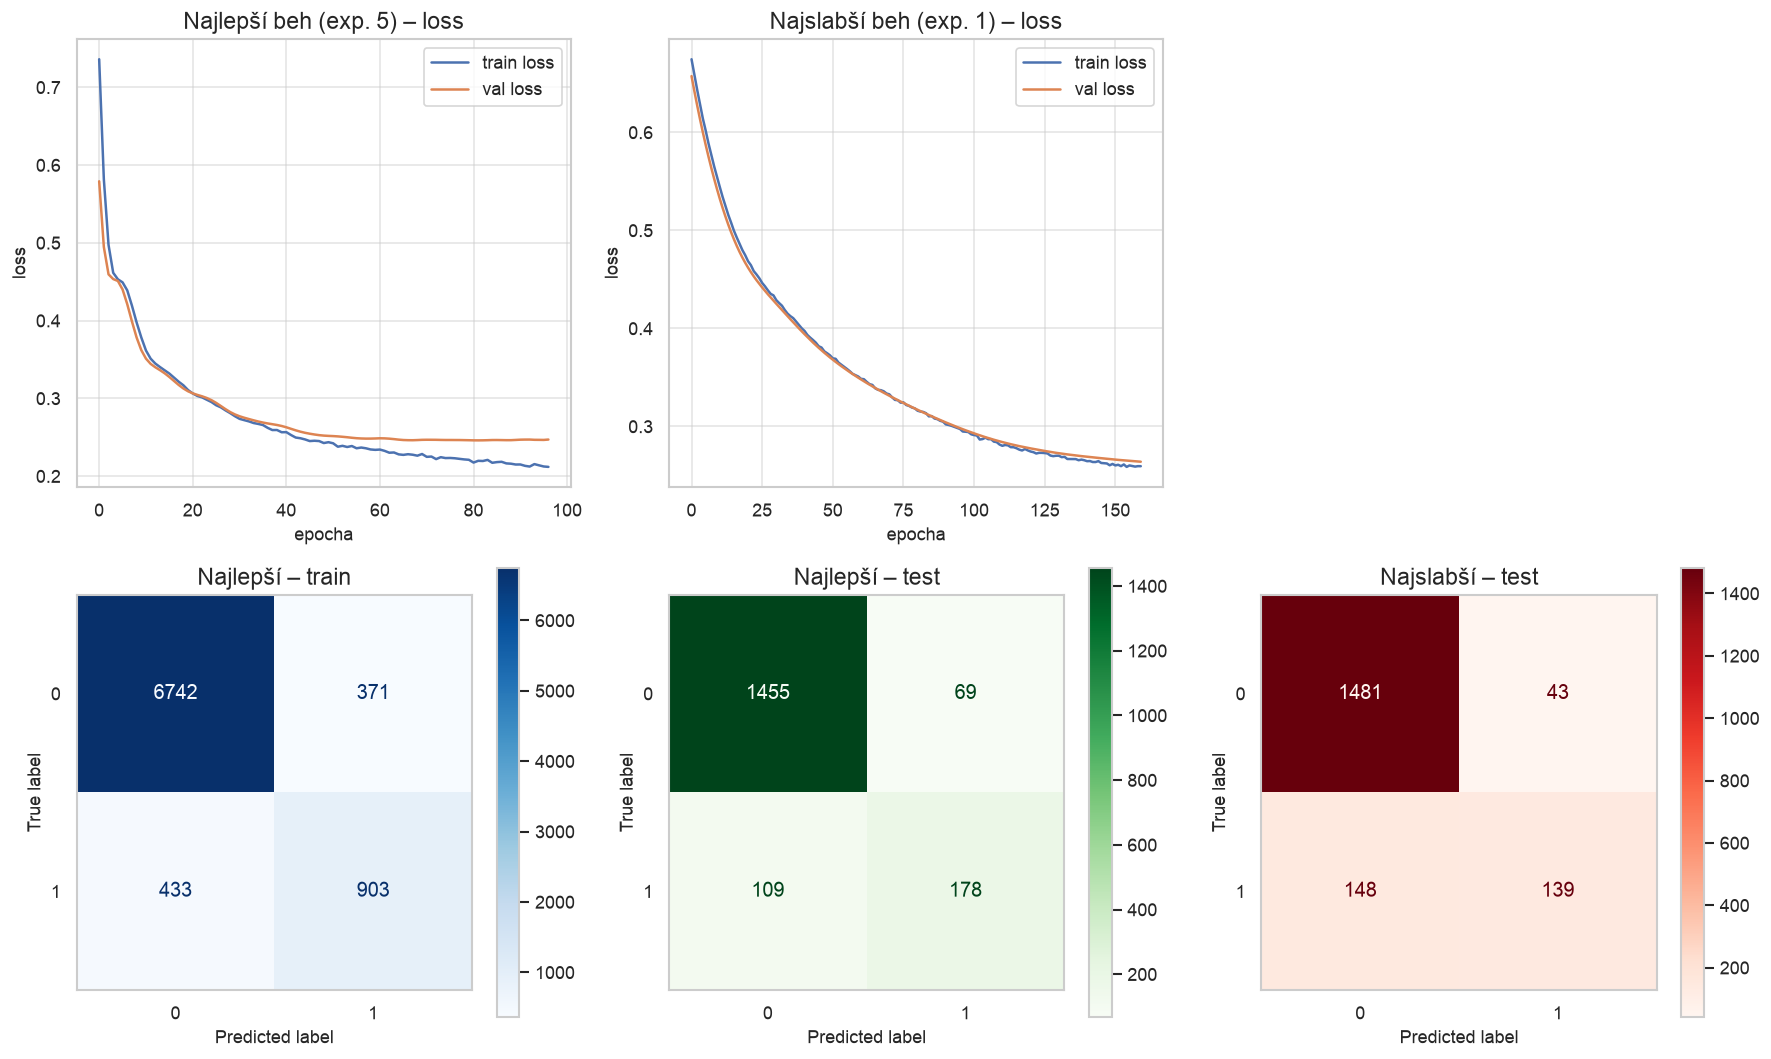

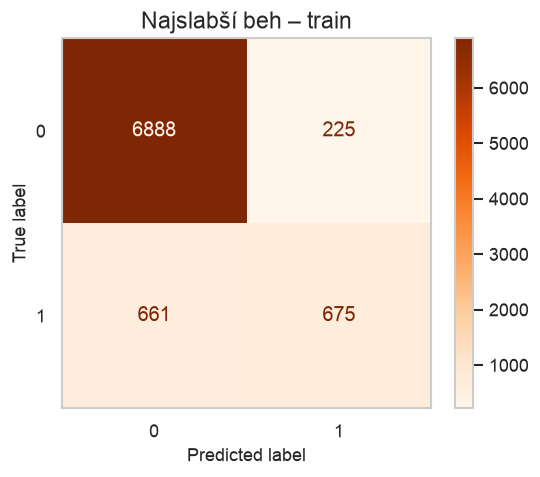

Najlepší beh podľa test F1: experiment 5; najslabší beh: experiment 1.


In [27]:
best_experiment = int(configuration_results.iloc[0]["experiment"])
worst_experiment = int(configuration_results.iloc[-1]["experiment"])
best_run = configuration_runs[best_experiment]
worst_run = configuration_runs[worst_experiment]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, label, experiment, run in [
    (axes[0, 0], "Najlepší", best_experiment, best_run),
    (axes[0, 1], "Najslabší", worst_experiment, worst_run),
]:
    ax.plot(run["history"]["train_loss"], label="train loss")
    ax.plot(run["history"]["val_loss"], label="val loss")
    ax.set(title=f"{label} beh (exp. {experiment}) – loss", xlabel="epocha", ylabel="loss")
    ax.legend()

axes[0, 2].axis("off")

for ax, label, target, score, color in [
    (axes[1, 0], "Najlepší – train", y_train, best_run["train"], "Blues"),
    (axes[1, 1], "Najlepší – test", y_test, best_run["test"], "Greens"),
    (axes[1, 2], "Najslabší – test", y_test, worst_run["test"], "Reds"),
]:
    ConfusionMatrixDisplay.from_predictions(target, score["pred"], ax=ax, cmap=color)
    ax.set_title(label)
    ax.grid(False)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    worst_run["train"]["pred"],
    ax=ax,
    cmap="Oranges",
)
ax.set_title("Najslabší beh – train")
ax.grid(False)
plt.show()

print(
    f"Najlepší beh podľa test F1: experiment {best_experiment}; "
    f"najslabší beh: experiment {worst_experiment}."
)